# Stage 01 - Prepare and validate 2022 demand

This notebook creates the hourly mainland Ecuador SNI demand profile used by the 2022 baseline. It also materializes the official carrier-supply reference that Stage 06 will use for the 5% validation gate.

The notebook checks every required input before processing. It uses the CENACE annual reports for 2022 demand, monthly peaks, and net electricity supply. The historical 2013 bus profile is only a temporal and spatial modeling template; it is not treated as observed 2022 demand.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.artifacts import format_preflight_report, run_preflight
from src.environment import check_environment, format_environment_report

environment = check_environment()
if not environment.ok:
    raise RuntimeError(format_environment_report(environment))
preflight = run_preflight("01_demand", root=ROOT)
preflight.raise_for_errors()
print(format_environment_report(environment))
print(format_preflight_report(preflight))

Environment preflight: PASS
  environment: pypsa-earth-ec (expected pypsa-earth-ec)
  python: 3.11.14 (required >=3.10,<3.12)
  pypsa: 0.30.3 (>=0.25,<=0.30.3) [ok]
  numpy: 1.26.4 (<2) [ok]
  pandas: 2.3.3 (>=2) [ok]
  xarray: 2025.1.2 (>=2023.11.0,<=2025.1.2) [ok]
  h5netcdf: 1.7.3 (>=1) [ok]
  PyYAML: 6.0.3 (>=6) [ok]
  requests: 2.32.5 (>=2) [ok]
  jsonschema: 4.25.1 (>=4) [ok]
  nbformat: 5.10.4 (>=5) [ok]
  nbclient: 0.10.2 (>=0.10) [ok]
Artifact preflight: PASS (stage=01_demand)
  not-required planning_adjustment_totals_source: stage does not require this artifact
  not-required planning_adjustment_pdf: stage does not require this artifact
  not-required planning_older_demand_pdf: stage does not require this artifact
  not-required planning_older_generation_pdf: stage does not require this artifact
  not-required planning_older_transmission_pdf: stage does not require this artifact
  not-required planning_adjustment_generation_source: stage does not require this artifact
  not-r

## Validation boundary and sources

The baseline represents the mainland Sistema Nacional Interconectado (SNI). Galapagos and other isolated systems are outside the model boundary. CENACE net generation is comparable with PyPSA power delivered to buses. Imports are an in-scope supply category. Exports, storage, curtailment, load shedding, and network losses are reported separately in the later energy balance.

The complete source identifiers, document links, page/table locators, carrier crosswalk, and tolerance formula are versioned in `config/validation_2022.yaml`.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from src.demand import (
    assert_demand_acceptance,
    load_hourly_template,
    load_monthly_targets,
    prepare_hourly_demand,
)
from src.validation import (
    build_supply_reference,
    load_raw_supply_reference,
    load_validation_contract,
)

contract = load_validation_contract(ROOT / "config" / "validation_2022.yaml")
print(contract["boundary"]["name"])
print(contract["boundary"]["accounting_basis"])
print(contract["boundary"]["time_basis"])

Ecuador mainland Sistema Nacional Interconectado (SNI)
Net electrical energy delivered to the SNI, plus imports.
8760 hourly snapshots in Ecuador mainland local standard time (UTC-05:00), stored as timezone-naive timestamps; Ecuador does not observe daylight saving time.


## Official 2022 supply reference

CENACE Table 2.4 reports net SNI supply by technology/fuel. The source rows remain unchanged in `data/raw/statistics/`. Phase 6 aggregates them into the official comparison categories `hydro`, `thermal`, `nonconventional` (wind, biomass, biogas, and solar), and `interconnection`. The displayed source rows sum 0.01 GWh below the reported total because each row is rounded to two decimals. That residual is visible and excluded from screening.

In [3]:
raw_supply = load_raw_supply_reference(ROOT / contract["supply_reference"]["raw_table"])
supply_reference = build_supply_reference(raw_supply, contract)
reference_output = ROOT / contract["supply_reference"]["normalized_table"]
reference_output.parent.mkdir(parents=True, exist_ok=True)
supply_reference.to_csv(reference_output, index=False)
supply_reference

,carrier,reference_gwh,source_components,source_ids,in_scope,evidence_class,notes
0,hydro,24499.54,hydroelectric,CENACE_ANNUAL_2022,True,official_fact,
1,thermal,3393.35,diesel;fuel_oil;natural_gas;naphtha;residue,CENACE_ANNUAL_2022,True,official_fact,
2,nonconventional,325.89,wind;biogas;biomass;solar_photovoltaic,CENACE_ANNUAL_2022,True,official_fact,
3,interconnection,465.83,imports_colombia;imports_peru,CENACE_ANNUAL_2022,True,official_fact,
4,source_rounding_residual,0.01,reported_total_minus_displayed_rows,CENACE_ANNUAL_2022,False,derived_reconciliation,Displayed source rows are rounded to 0.01 GWh.


## Demand transformation

CENACE monthly values are rounded to 0.01 GWh and sum to 27,561.64 GWh, while CENACE reports an annual control of 27,561.62 GWh. One common factor reconciles all months to the annual total without changing their relative weights.

Within each month, an affine transformation reshapes the historical national profile so both energy and peak match the official controls. The historical bus shares are then reapplied at every hour. Output power is written in MW, the native PyPSA convention; no downstream `/1000` conversion is permitted. The target year has 8,760 local-standard-time hours and no daylight-saving transition.

In [4]:
targets = load_monthly_targets(ROOT / contract["demand"]["monthly_targets"])
template = load_hourly_template(ROOT / contract["demand"]["template"])
result = prepare_hourly_demand(
    template,
    targets,
    target_year=contract["year"],
    annual_energy_gwh=contract["demand"]["annual_energy_gwh"],
)
assert_demand_acceptance(result)
result.monthly_diagnostics[[
    "month", "published_energy_gwh", "target_energy_gwh",
    "modeled_energy_gwh", "target_peak_mw", "modeled_peak_mw"
]]

,month,published_energy_gwh,target_energy_gwh,modeled_energy_gwh,target_peak_mw,modeled_peak_mw
0,January,2309.96,2309.958324,2309.958324,4161.71,4161.71
1,February,2130.88,2130.878454,2130.878454,4152.33,4152.33
2,March,2416.38,2416.378247,2416.378247,4252.73,4252.73
3,April,2385.90,2385.898269,2385.898269,4388.06,4388.06
4,May,2392.72,2392.718264,2392.718264,4238.00,4238.00
5,June,2156.92,2156.918435,2156.918435,4077.14,4077.14
6,July,2269.63,2269.628353,2269.628353,4114.26,4114.26
7,August,2298.02,2298.018332,2298.018332,4075.82,4075.82
8,September,2253.38,2253.378365,2253.378365,4146.78,4146.78
9,October,2305.14,2305.138327,2305.138327,4113.94,4113.94


In [5]:
profile_output = ROOT / contract["demand"]["output"]
profile_output.parent.mkdir(parents=True, exist_ok=True)
result.profile_mw.to_csv(profile_output, index=True, index_label="timestamp")
pd.Series(result.summary, name="value").to_frame()

,value
target_year,2022
source_template_year,2013
snapshots,8760
buses,251
annual_energy_gwh,27561.62
annual_target_gwh,27561.62
annual_energy_error_gwh,0.0
annual_peak_mw,4388.06
negative_values,0
missing_values,0


## Reproducible validation figures

The first figure confirms monthly energy and peak controls. The second shows the resulting national load-duration curve. Both figures are saved for the Phase 3 technical report.

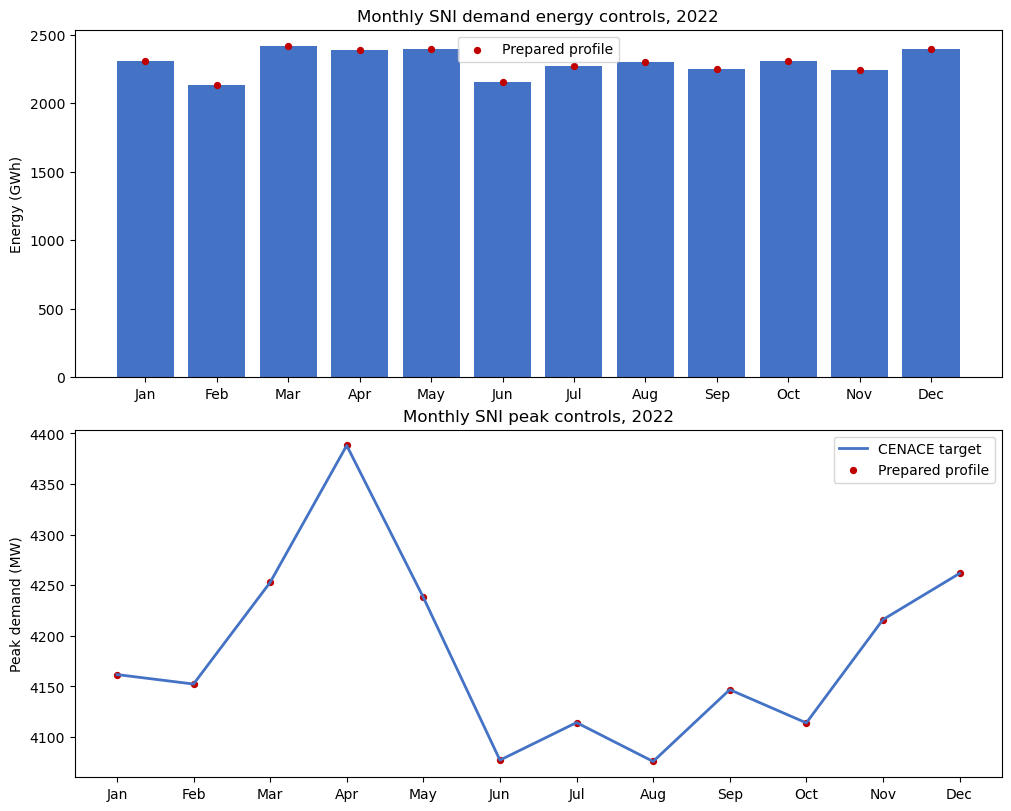

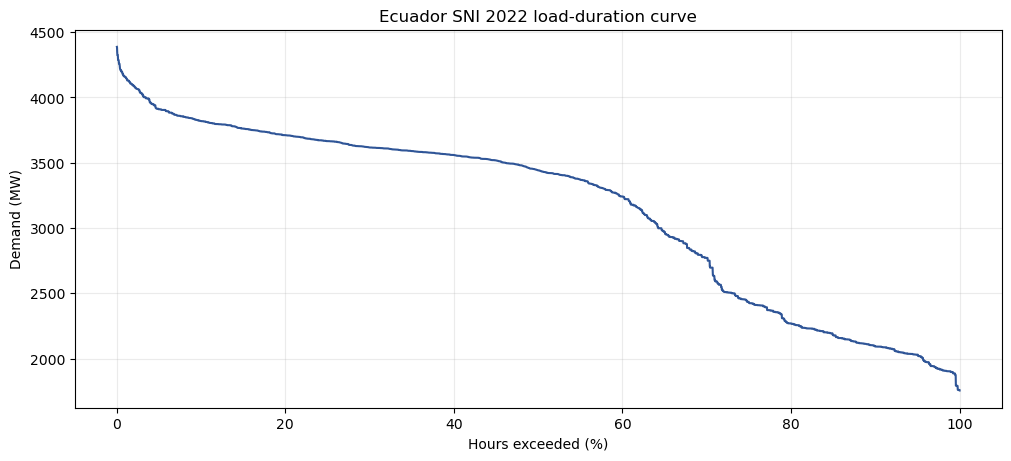

In [6]:
figure_dir = ROOT / "reports" / "figures" / "phase_03"
figure_dir.mkdir(parents=True, exist_ok=True)
diagnostics = result.monthly_diagnostics

fig, axes = plt.subplots(2, 1, figsize=(10, 8), constrained_layout=True)
positions = range(12)
axes[0].bar(positions, diagnostics["target_energy_gwh"], color="#4472C4")
axes[0].scatter(positions, diagnostics["modeled_energy_gwh"], color="#C00000", s=18, label="Prepared profile")
axes[0].set_ylabel("Energy (GWh)")
axes[0].set_xticks(list(positions), diagnostics["month"].str[:3])
axes[0].set_title("Monthly SNI demand energy controls, 2022")
axes[0].legend()
axes[1].plot(positions, diagnostics["target_peak_mw"], color="#4472C4", linewidth=2, label="CENACE target")
axes[1].scatter(positions, diagnostics["modeled_peak_mw"], color="#C00000", s=18, label="Prepared profile")
axes[1].set_ylabel("Peak demand (MW)")
axes[1].set_xticks(list(positions), diagnostics["month"].str[:3])
axes[1].set_title("Monthly SNI peak controls, 2022")
axes[1].legend()
fig.savefig(figure_dir / "demand_monthly_validation.png", dpi=160, bbox_inches="tight")
plt.show()

national = result.profile_mw.sum(axis=1).sort_values(ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
ax.plot((national.index + 1) / len(national) * 100, national, color="#2F5597")
ax.set_xlabel("Hours exceeded (%)")
ax.set_ylabel("Demand (MW)")
ax.set_title("Ecuador SNI 2022 load-duration curve")
ax.grid(alpha=0.25)
fig.savefig(figure_dir / "demand_duration_curve.png", dpi=160, bbox_inches="tight")
plt.show()

## Acceptance result

This stage passes only when the profile has 8,760 consecutive hourly timestamps, no missing or negative values, exact annual and monthly energy controls, exact monthly peak controls, and unchanged hourly bus shares. Passing this notebook does not validate a PyPSA solve; the carrier gate is applied only after the Stage 06 annual simulation.

In [7]:
print("Stage 01 demand preparation: PASS")
print(f"Annual energy: {result.summary['annual_energy_gwh']:.2f} GWh")
print(f"Annual peak: {result.summary['annual_peak_mw']:.2f} MW")
print(f"Hourly bus-share change: {result.summary['maximum_hourly_bus_share_change']:.3e}")
print("The 2022 network has not yet been simulated or carrier-validated.")

Stage 01 demand preparation: PASS
Annual energy: 27561.62 GWh
Annual peak: 4388.06 MW
Hourly bus-share change: 6.245e-17
The 2022 network has not yet been simulated or carrier-validated.
